# 교차 검증과 그리드 서치


모델의 하이퍼파라미터를 결정하는 가장 좋은 방법은 모델을 만들 때 모두 다른 하이퍼파라미터를 세팅하고 이를 특정한 다른 데이터로 검증하여 가장 정확도가 높은 부분을 찾는 것이다.

이전까지는 모델의 테스트 데이터를 하이퍼파라미터 결정에 이용하였다. 하지만 이는 모델의 하이퍼파라미터가 모델의 테스트 세트에만 맞춰진다.

테스트 세트는 모델의 마지막 모델이 실전 사용에서의 일반화된 사용 사례를 들어 평가하는 것이므로, 테스트 세트는 모델 훈련 후 가장 마지막 단계에서 이용해야 한다. 이를 위해 **검증 세트(validation set)** 를 이용한다.

## 검증 세트(validation set)
테스트 세트를 사용하지 않으면 모델이 과대적합(overfitting)인지 과소적합(underfitting)인지 판단하기 어렵다.\
테스트 세트를 사용하지 않고 이를 측정하는 방법은 훈련 세트를 다시 나누어 따로 데이터를 뽑아내는 것이다.\
훈련 세트에서 테스트 세트를 나누고, 또 그 나머지에서 다시 검증 세트를 만들어낸다.

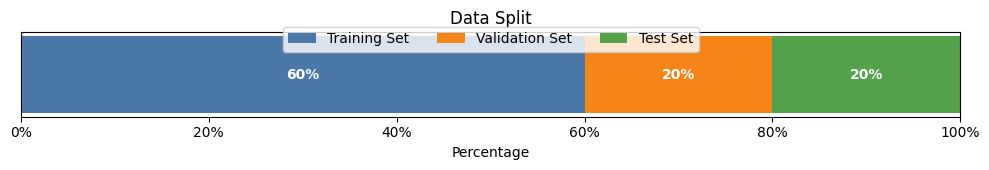\
위 이미지와 유사한 비율로 분리한다.

## 훈련 방식:
훈련 세트에서 모델을 훈련하고 검증 세트로 모델을 평가한다. 이런 방식으로 테스트하고 싶은 매개변수를 바꾸어 가며 하이퍼파라미터를 선택해 가장 좋은 모델을 고른다.\
다음 결정된 그 매개변수를 이용하여 훈련 세트와 검증 세트를 합쳐 전체 훈련 데이터에서 모델을 다시 훈련한다.\
그리고 마지막에 테스트 세트에서 최종 점수를 평가하여 사용한다.

데이터 세트를 불러오고 검증 세트를 제작한다.

In [37]:
import pandas as pd
wine = pd.read_csv('https://raw.githubusercontent.com/rickiepark/hg-mldl/master/wine.csv')
wine.head()

,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0
1,9.8,2.6,3.20,0.0
2,9.8,2.3,3.26,0.0
3,9.8,1.9,3.16,0.0
4,9.4,1.9,3.51,0.0


가진 4가지의 열에서 `class`열을 타깃으로 하여 나머지 열은 특성으로 사용한다.

In [38]:
data = wine[['alcohol', 'sugar', 'pH']]
target = wine['class']

훈련 세트와 테스트 세트를 나눈다.

In [39]:
from sklearn.model_selection import train_test_split
train_input, test_input, train_target, test_target = train_test_split(data, target, test_size=0.2, random_state=42)

다음 `train_input`과 `train_target`을 다시 `train_test_spilit()`에 넣어 훈련 세트와 검증 세트를 생성한다.

In [40]:
train_sub_input, val_input, train_sub_target, val_targete = train_test_split(train_input, train_target, test_size=0.2, random_state=42)

단순히 `train_test_spilit()`을 2번 사용하여 세트를 두 번 나누는 작업이다.

각 세트의 크기를 확인해보면:

In [41]:
print(train_sub_input.shape, val_input.shape, test_input.shape)

(4157, 3) (1040, 3) (1300, 3)


이제 각 데이터를 이용해 모델을 훈련하겠다.
> 모델 점수 확인 시에는 검증 세트를 이용한다.

In [42]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier()
dt.fit(train_sub_input, train_sub_target)
print(dt.score(train_sub_input, train_sub_target))
print(dt.score(val_input, val_targete))

0.9971133028626413
0.8615384615384616


모델이 만들어졌다.
> 일부 과대적합이다.

## 교차 검증
검증 세트를 만들기 위해서 훈련 세트에서 일부를 사용하였다. 이로 인해 훈련 세트가 줄어들었다.
일반적으로 많은 데이터를 훈련할수록 좋은 모델이 만들어진다.\
이럴 때, **교차 검증(cross validation)** 을 이용하면 안정적인 검증이 가능하다.

교차 검증은 검증 세트를 분리하여 평가하는 과정을 여러 번 반복한다. 다음 이 점수를 평균화하여 최종 점수를 산출한다.\
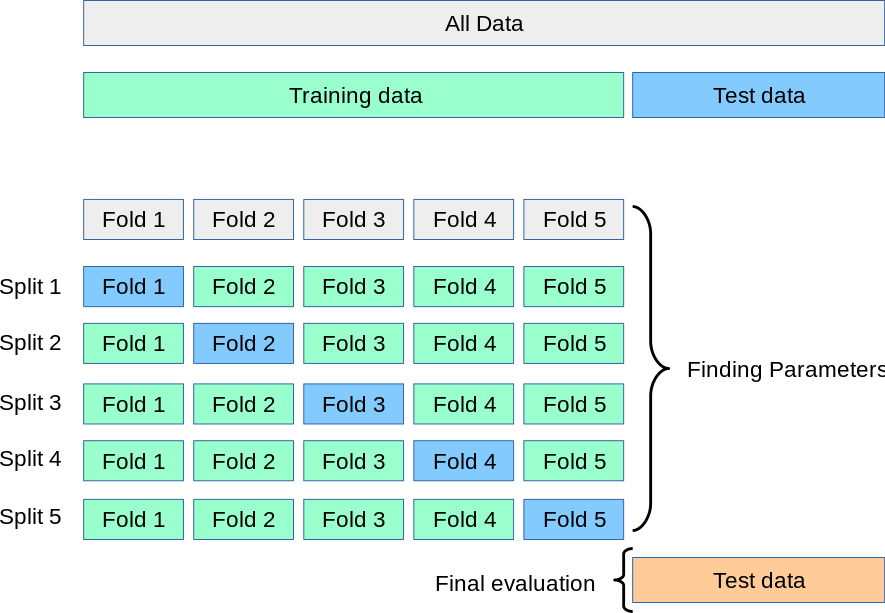\
위 그림은 교차 검증 방법 중 하나인 k-폴드 교차 검증 방법이다.

전체 훈련 세트를 k개로 나눈 후 각 모델을 훈련하여 교차 검증을 수행한다.

`sklearn`에서는 `cross_validate()` 교차 검증 함수를 이용하여 교차 검증을 진행할 수 있다.\
평가할 모델 객체를 첫 번째 매개변수로 전달하고, 훈련 세트 전체를 다음 매개변수들에 순서대로 입력한다.

In [43]:
from sklearn.model_selection import cross_validate
scores = cross_validate(dt, train_input, train_target)
print(scores)

{'fit_time': array([0.00726724, 0.00745559, 0.00770831, 0.00720835, 0.00577736]), 'score_time': array([0.00249815, 0.00179768, 0.00206637, 0.00392675, 0.00220442]), 'test_score': array([0.86634615, 0.85096154, 0.87680462, 0.85370549, 0.83830606])}


출력된 값을 확인해보자.

첫 번째와 두 번째 출력은 `fit_time`과 `score_time`이다. 말 그대로 훈련 시간과 검증 시간을 출력한 것이다.\
나머지 출력인 `test_score`은 검증이 진행된 점수들이다.
>5개의 결과 점수가 저장되어 있으므로 `5-fold cross validation`을 수행한 것이다.
> 기본적으로 `k-fold cross validation`을 진행할 때 `cross_validate()` 함수의 경우 기본값은 5이다.
최종 점수는 검증이 진행된 5개의 점수들을 평균하여 구할 수 있다.

In [44]:
import numpy as np
print(np.mean(scores['test_score']))

0.8572247723402681


여기서 주의할 점은, `cross_validate()`는 훈련 세트를 섞어 폴드를 나누지 않았다는 점이다.
교차 검증을 할 때 훈련 세트를 섞으려면 **분할기(splitter)** 를 지정해야 한다.

사이킷런의 분할기는 교차 검증에서 폴드를 어떻게 나눌지 결정한다.\
`cross_validate()` 함수의 경우 기본적으로 회귀 모델일 경우 `KFold` 분할기를 사용하고 분류 모델일 경우 타깃 클래스를 모두 나누기 위해 `StratifiedKfold`를 이용한다.

다음 코드의 과정과 같다:

In [45]:
from sklearn.model_selection import StratifiedKFold
scores = cross_validate(dt, train_input, train_target, cv=StratifiedKFold())
print(np.mean(scores['test_score']))

0.8574167098541496


훈련 세트를 다시 섞은 후 10-fold cross validation을 수행하면 다음과 같다.

In [46]:
splitter = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
scores_10k = cross_validate(dt, train_input, train_target, cv=splitter)
print(np.mean(scores_10k['test_score']))

0.8572295094115903


계속해서 `DecisionTree`의 하이퍼파라미터 값을 변경해가며 최적의 모델을 제작해본다.

## 하이퍼파라미터 튜닝


모델이 학습하는 파라미터는 모델 파라미터, 사용자가 모델에게 직접 지정하는 파라미터는 하이퍼파라미터이다.\
이 하이퍼파라미터의 최적값을 찾고 이를 모델에 적용하는 과정이 필요하다.

머신러닝 라이브러리에서는 하이퍼파라미터를 모두 클래스의 메서드의 매개변수로 표현한다.\
하이퍼파라미터 훈련에는:
1. 라이브러리가 제공하는 기본값을 그대로 이용하여 모델을 1차적으로 훈련한다.
2. 검증 세트의 점수나 교차 검증을 통해 최적의 매개변수 값을 도출해낸다.

위와 같은 과정으로 진행된다. 각 값을 변경해가면서 최적의 값을 찾아내야 한다.
> 위와 같이 사람의 개입 없이 하이퍼파라미터 튜닝을 진행하는 것을 AutoML 라고 한다.

다만 이 과정에서 한가지 큰 문제가 발생한다.\
예를 들어, DecisiontreeClassifier 모델에서 최적의 `max_depth` 하이퍼파라미터 값을 찾았다고 할때, `max_depth` 값을 고정하고 다음 하이퍼파라미터인 `min_sample_spilt`을 찾는다. 하지만 `min_sample_spilt`의 값에 따라 `max_depth`의 값도 변하므로 이 방법은 올바르지 않다.

즉, 두 매개변수를 동시에 바꾸어 가며 최적의 값을 찾아야만 한다.\
또한, 매개변수가 많아지면 계산해야 할 작업은 기하급수적으로 늘어나게 된다.

sklearn 에서는 이 과정을 쉽게 할 수 있게 해주는 **그리드 서치(Grid Search)** 를 제공한다.
> 그리드 서치에 대한 자세한 정보는 아래 링크에서 확인 가능하다.
> [링크](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

sklearn의 `GridSearchCV` 클래스는 하이퍼파라미터 탐색과 교차 검증을 한 번에 수행 가능하게 한다.

기본 매개변수를 사용한 결정 트리 모델에서 `min_impurity_decrease`의 최적 매개변수값을 찾아본다.

In [47]:
from sklearn.model_selection import GridSearchCV

params = {'min_impurity_decrease': [0.0001, 0.0002, 0.0003, 0.0004, 0.0005]}

`0.0001`씩 증가하는 5개의 값을 이용한다.

`GridSearchCV` 클래스에 그리드 서치 대상 모델과 파라미터를 입력한다.

In [48]:
gs = GridSearchCV(DecisionTreeClassifier(random_state=42), params, n_jobs=-1) # 모든 코어를 이용하여 작업 수행(-1)

결정 트리 클래스의 객체를 생성하여 바로 `GridSearchCV`로 전달했다.\
생성된 `gs` 인스턴스에서 `fit()`을 바로 호출하여 그리드 서치 작업을 시작할 수 있다.

`GridSearchCV`의 `cv` 매개변수 기본값은 5이다. 따라서, 5-fold cross validatoin을 수행한다.
>5번씩 5개의 하이퍼파라미터를 훈련하므로 25개의 모델을 훈련한다.

In [49]:
gs.fit(train_input, train_target)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'min_impurity_decrease': [0.0001, 0.0002, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : the fo

교차 검증 과정에서 최적의 하이퍼파라미터를 찾은 후 자동으로 완성된 모델이 `best_estimator_` 속성에 저장된다.\
가장 최적의 하이퍼파라미터 값은 `best_params_`에 저장되어있다.

In [50]:
dt_gs = gs.best_estimator_
print(dt_gs.score(train_input, train_target))
print(gs.best_params_)

0.9615162593804117
{'min_impurity_decrease': 0.0001}


이 모델에서는 `0.0001`이 가장 최적의 값으로 선택되었다.\
각 훈련에서 수행한 교차 검증의 평균 점수는 `cv_results_`에 저장되어 있다.

In [51]:
print(gs.cv_results_['mean_test_score'])

[0.86819297 0.86453617 0.86492226 0.86780891 0.86761605]


첫 번째 값(`0.0001`)이 가장 크다.\
또한, `best_index_` 속성을 이용해 가장 높은 값의 인덱스를 찾을 수 있다.

In [52]:
print(gs.best_index_)
print(gs.cv_results_['params'][gs.best_index_])

0
{'min_impurity_decrease': 0.0001}


위와 같이 그리드 서치로 찾은 값들을 얻어낼 수 있다.

지금까지의 과정은:
1. 탐색할 매개변수를 지정한다.
2. 훈련 세트에서 그리드 서치를 수행하여 최적의 하이퍼파라미터 값을 찾는다.
3. 그리드 서치는 최상의 매개변수에서 전체 훈련 세트를 사용해 최종 모델을 훈련한다.
4. 훈련된 모델을 그리드 서치 객체에서 사용한다.

위와 같이 정리할 수 있다.\
다음으로는 `min_impurity_decrease`와 추가하여 `max_depth`의 값, `min_samples_split` 또한 찾아낸다.\
3가지의 하이퍼파라미터 값을 찾는 것이다.

In [53]:
params_deep = {'min_impurity_decrease': np.arange(0.0001, 0.001, 0.0001), 'max_depth': range(5, 20, 1), 'min_samples_split': range(2, 100, 10)}

`numpy`의 `arange()` 함수는 첫 번째 매개변수 값에서 시작하여 두 번째 매개변수를 포함하지 않고 두 번째 매개변수 바로 이전에 도달할 때까지 세 번째 매개변수를 더한 배열을 만든다.
>`arange()`의 경우는 부동소숫점 배열 제작이 가능한다.

기본 함수인 `range()` 함수 또한 기능은 같지만, 부동소수점 배열 생성은 불가능하고 정수 배열만 생성이 가능하다.

이 3가지 매개변수로 수행할 교차 검증 횟수는 $9 \times 15 \times 10 = 1350$회이다.\
기본적으로 5-fold cross validation을 수행하므로 $1350 \times 5 = 6750$회를 수행한다.

In [54]:
gs_deep = GridSearchCV(DecisionTreeClassifier(random_state=42), params_deep, n_jobs=-1)
gs_deep.fit(train_input, train_target)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': range(5, 20), 'min_impurity_decrease': array([0.0001... 0.0009]), 'min_samples_split': range(2, 100, 10)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter 

최상의 매개변수 조합을 확인해 보겠다.

In [55]:
print(gs_deep.best_params_)

{'max_depth': 14, 'min_impurity_decrease': np.float64(0.0004), 'min_samples_split': 12}


최상의 교차 검증 점수도 확인한다.

In [56]:
print(np.max(gs_deep.cv_results_['mean_test_score']))
print(np.min(gs_deep.cv_results_['mean_test_score']))

0.8683865773302731
0.8541463685496409


매개변수를 일일이 바꾸어 가며 교차 검증을 수행하지 않고 원하는 매개변수 값만들 나열하며녀 자동으로 교차 검증을 수행하여 최상의 매개변수를 찾아낼 수 있다.

하지만 이 방식에도 문제는 존재한다. 앞서 나열한 배개변수들의 간격은 모두 정해져 있었지만, 이를 정한 특별한 근거는 존재하지 않았다.\
이보다 더 세세하거나 더 넓은 간격으로 시도한다면 더 정확하게 모델을 만들 수 있을 것이다.

## 랜덤 서치
매개변수의 값이 수치일 때, 값의 일정한 범위나 간격을 정하기 어려울 수 있다.\
또한, 너무나 많은 매개 변수가 존재하여 그리드 서치 과정에서 많은 시간이 걸릴 수 있다.\
이것을 해결하기 위해 **랜덤 서치(random search)**를 이용한다.

랜덤 서치에는 매개변수를 직접 전달하지 않고 매개변수를 샘플링 가능한 확률 분포를 전달한다.
>이를 위해서는 `scipy` 라이브러리 이용이 필요하다.
>`scipy`는 적분, 보간, 확률, 선형 대수 등을 제공하는 파이선의 과학 라이브러리이다.

In [57]:
from scipy.stats import uniform, randint

`scipy.stats`에 있는 `uniform`과 `randint`는 모두 주어진 범위 내에서 균등하게 값을 샘플링한다.(균등 분포 샘플링)\
`randint`는 정수 값을, `uniform`은 실수 값을 뽑는다.(부동 소숫점 포함)

0와 10 사이의 범위를 갖는 `randint` 객체를 만들고 10개의 숫자를 샘플링해본다.

In [58]:
rgen = randint(0, 10)
rgen.rvs(10)

array([1, 9, 0, 4, 0, 1, 1, 8, 7, 4])

더 많은 값을 샘플링하고 각 숫자가 몇 번 나오게 되는지 확인한다.

In [59]:
np.unique(rgen.rvs(1000), return_counts=True)

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 array([109,  99,  98, 110, 103,  86,  92, 112, 106,  85]))

어느 정도 고르게 숫자를 샘플링한 것을 볼 수 있다.\
`uniform`또한 비슷하다.

In [60]:
ugen = uniform(0, 1)
ugen.rvs(10)

array([0.62321407, 0.97332714, 0.52403906, 0.00309782, 0.8525214 ,
       0.96212384, 0.13090958, 0.23279159, 0.38635621, 0.70027382])

랜덤 서치에 각각 객체를 넘겨주고 총 몇 번의 샘플링으로 최적의 하이퍼파라미터를 찾도록 지정할 수 있다.
>샘플링 횟수는 시스템 자원의 한계까지 밀어붙인다.

이제 탐색말 매개변수를 모두 딕셔너리로 선언하겠다.\
`min_impurity_decrease`와 추가하여 `max_depth`의 값, `min_samples_split`, `min_samples_leaf` 매개변수까지 모두 찾아낸다.
>`min_samples_leaf`는 리프 노드가 되기 위한 최소 샘플의 개수이다.
> 어떠한 노드가 분할하여 만들어질 자식 노드의 개수가 이 값보다 작을 경우 다시 분기하지 않는다.

In [61]:
params_random = {'min_impurity_decrease': uniform(0.0001, 0.001), 'max_depth': randint(20, 50), 'min_samples_split': randint(2, 25), 'min_samples_leaf': randint(1, 25)}

min_impurity_decrease는 0.0001부터 0.001까지의 실수, max_depth는 20부터 50까지, min_samples_split은 2부터 25까지, min_samples_leaf는 1부터 25까지 샘플링한다.

샘플링 횟수는 `RandomizedSearchCV`의 `n_iter`에 저장된다.

In [62]:
from sklearn.model_selection import RandomizedSearchCV
rs = RandomizedSearchCV(DecisionTreeClassifier(random_state=42), params_random, n_iter=100, n_jobs=-1, random_state=42)
rs.fit(train_input, train_target)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': <scipy.stats....002026F3E1910>, 'min_impurity_decrease': <scipy.stats....002026F4E0640>, 'min_samples_leaf': <scipy.stats....002026F3547C0>, 'min_samples_split': <scipy.stats....002026F22BBD0>}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",100
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User G

위에서 정의된 매개변수의 총 범위에서 총 100번을 샘플링하고 교차 점증을 수행하고 최적의 매개변수를 찾는다.

최적의 매개변수 조합:

In [63]:
print(rs.best_params_)

{'max_depth': 39, 'min_impurity_decrease': np.float64(0.00034102546602601173), 'min_samples_leaf': 7, 'min_samples_split': 13}


최고의 교차 검증 점수

In [64]:
print(np.max(rs.cv_results_['mean_test_score']))

0.8695428296438884


최적의 모델을 사용하면:

In [65]:
dt_random_best = rs.best_estimator_
print(dt_random_best.score(test_input, test_target))

0.86


일반적으로 테스트 세트의 점수는 검증 세트의 점수보다 낮다.\
완벽한 모델은 아니지만 여러 가지 매개변수를 테스트하여 그리드 서치 및 교차 검증 과정을 통해 모델을 만들어냈다.

이 실험에서는 결정 트리 모델의 여러 가지 매개변수를 바꾸어가며 성능을 비교하였다. 그리드 서치와 랜덤 서치를 통해 다양한 조합을 시험해 보고, 교차 검증을 이용하여 각 조합의 성능을 안정적으로 평가하였다. 그 결과 최적의 매개변수 조합을 찾았고, 이를 테스트 세트에 적용하여 모델의 성능을 확인하였다. 일반적으로 테스트 세트의 점수는 검증 세트의 점수보다 낮지만, 여러 가지 매개변수를 비교해 가장 적절한 모델을 선택할 수 있었다.

### 용어 정의

매개변수: 모델이 학습할 때 사용하는 설정값으로, 트리의 깊이나 분할 기준 등을 의미한다.

그리드 서치: 여러 매개변수 조합을 미리 정해진 범위 안에서 하나씩 시험해 최적의 조합을 찾는 방법이다.

랜덤 서치: 가능한 매개변수 조합을 무작위로 샘플링하여 비교하는 방법이다.

교차 검증: 데이터를 여러 번 나누어 각각의 부분을 검증 데이터로 사용해 모델 성능을 평가하는 방법이다.

검증 세트: 모델을 선택하거나 조정할 때 사용하는 데이터이다.

테스트 세트: 최종적으로 모델의 성능을 평가하기 위해 사용하는 데이터이다.